# 4.5.- Comparativa MNIST - Manual vs Random Search

Para evaluar si el ajuste de hiperparámetros ha mejorado el rendimiento del modelo,  
compararemos ambos clasificadores:

1. **Modelo base** — arquitectura fija definida manualmente.  
2. **Modelo optimizado** — arquitectura y parámetros elegidos mediante *Random Search*.

Analizaremos:

- **Pérdida (Loss)** y **Exactitud (Accuracy)** sobre el conjunto de test.  
- **Matrices de confusión**, que muestran los aciertos (diagonal) y errores (fuera de la diagonal) por clase.

Una mejora real debería reflejarse en:
- Una **mayor exactitud**.  
- Una **matriz de confusión** con más valores concentrados en la diagonal principal.

In [1]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras

In [3]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_test = X_test.astype("float32") / 255.0
X_test = X_test.reshape(-1, 28 * 28)

num_classes = 10
y_test = keras.utils.to_categorical(y_test, num_classes)

X_test.shape, y_test.shape

((10000, 784), (10000, 10))

Modelo BASE       -> Loss: 0.0621  |  Accuracy: 0.9813
Modelo OPTIMIZADO -> Loss: 0.0603  |  Accuracy: 0.9830


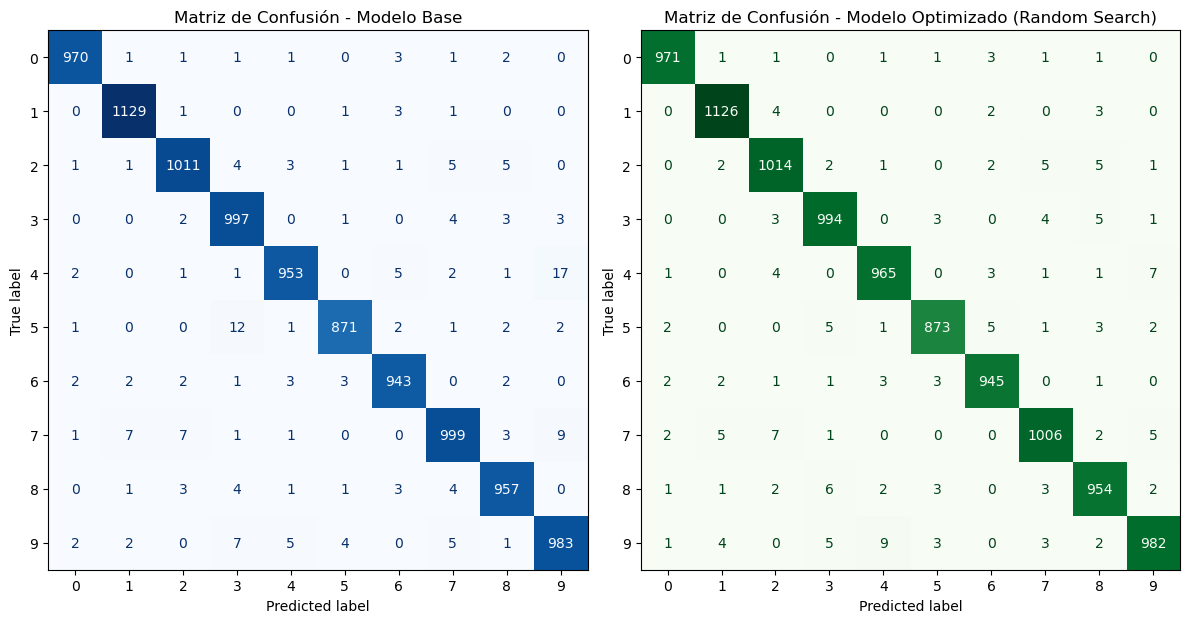

Diferencia de accuracy: +0.0017
El modelo optimizado mejora el rendimiento respecto al modelo base.


In [4]:
# Cargar ambos modelos
base_model = keras.models.load_model("nmist_base_model.keras")
tuned_model = keras.models.load_model("mnist_rs_best.keras")

# Predicciones
y_true = np.argmax(y_test, axis=1)
y_pred_base = np.argmax(base_model.predict(X_test, verbose=0), axis=1)
y_pred_tuned = np.argmax(tuned_model.predict(X_test, verbose=0), axis=1)

# Evaluación en test
base_loss, base_acc = base_model.evaluate(X_test, y_test, verbose=0)
tuned_loss, tuned_acc = tuned_model.evaluate(X_test, y_test, verbose=0)

print(f"Modelo BASE       -> Loss: {base_loss:.4f}  |  Accuracy: {base_acc:.4f}")
print(f"Modelo OPTIMIZADO -> Loss: {tuned_loss:.4f}  |  Accuracy: {tuned_acc:.4f}")

# Matrices de confusión
cm_base = confusion_matrix(y_true, y_pred_base)
cm_tuned = confusion_matrix(y_true, y_pred_tuned)

# Visualización lado a lado
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ConfusionMatrixDisplay(cm_base).plot(ax=ax[0], cmap="Blues", colorbar=False)
ConfusionMatrixDisplay(cm_tuned).plot(ax=ax[1], cmap="Greens", colorbar=False)

ax[0].set_title("Matriz de Confusión - Modelo Base")
ax[1].set_title("Matriz de Confusión - Modelo Optimizado (Random Search)")

plt.tight_layout()
plt.show()

# Comparación numérica
diff = tuned_acc - base_acc
print(f"Diferencia de accuracy: {diff:+.4f}")
if diff > 0:
    print("El modelo optimizado mejora el rendimiento respecto al modelo base.")
else:
    print("El modelo optimizado no supera al modelo base en este conjunto de prueba.")

## Predicción individual y visualización de probabilidades

Tomaremos una imagen aleatoria del conjunto de **test** y mostraremos:

1. La **imagen original**.  
2. La **etiqueta real** y la **predicción** del modelo.  
3. Un **gráfico de barras** con las probabilidades asociadas a cada dígito (0–9).

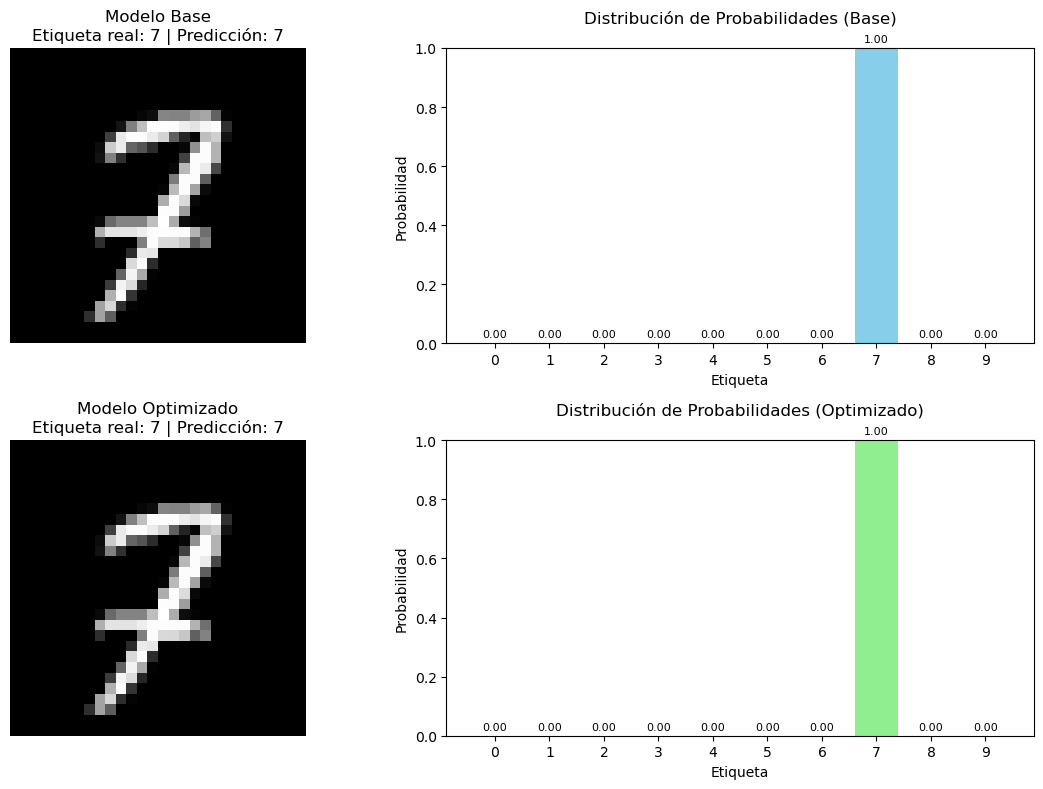

In [18]:
# Seleccionar índice aleatorio
idx = np.random.randint(0, X_test.shape[0])

# Imagen y etiqueta real
img = X_test[idx].reshape(1, -1)
true_label = np.argmax(y_test[idx])

# Predicciones de ambos modelos
pred_base = base_model.predict(img, verbose=0)[0]
pred_tuned = tuned_model.predict(img, verbose=0)[0]

pred_label_base = np.argmax(pred_base)
pred_label_tuned = np.argmax(pred_tuned)

# Crear figura
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# --- Modelo base ---
axes[0, 0].imshow(X_test[idx].reshape(28, 28), cmap="gray")
axes[0, 0].set_title(f"Modelo Base\nEtiqueta real: {true_label} | Predicción: {pred_label_base}")
axes[0, 0].axis("off")

axes[0, 1].bar(range(10), pred_base, color="skyblue")
axes[0, 1].set_xticks(range(10))
axes[0, 1].set_xlabel("Etiqueta")
axes[0, 1].set_ylabel("Probabilidad")
axes[0, 1].set_title("Distribución de Probabilidades (Base)\n")
axes[0, 1].set_ylim(0, 1)
for i, p in enumerate(pred_base):
    axes[0, 1].text(i, p + 0.02, f"{p:.2f}", ha="center", fontsize=8)

# --- Modelo optimizado ---
axes[1, 0].imshow(X_test[idx].reshape(28, 28), cmap="gray")
axes[1, 0].set_title(f"Modelo Optimizado\nEtiqueta real: {true_label} | Predicción: {pred_label_tuned}")
axes[1, 0].axis("off")

axes[1, 1].bar(range(10), pred_tuned, color="lightgreen")
axes[1, 1].set_xticks(range(10))
axes[1, 1].set_xlabel("Etiqueta")
axes[1, 1].set_ylabel("Probabilidad")
axes[1, 1].set_title("Distribución de Probabilidades (Optimizado)\n")
axes[1, 1].set_ylim(0, 1)
for i, p in enumerate(pred_tuned):
    axes[1, 1].text(i, p + 0.02, f"{p:.2f}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()